# K-MEANS CLUSTERING: TIPOS DE MUNICIPIO SEGÚN SUS CARENCIAS DE SERVICIOS - CENSO 2024

**Pregunta:** ¿qué tipos de municipio de Bolivia se pueden distinguir según **cuál** servicio básico les falta, y qué grupos conviene revisar primero?

**Por qué este análisis complementa a los anteriores:** los clasificadores y la regresión estiman si una vivienda o un municipio tiene muchas carencias, pero no indican qué servicio falta. El IPS resume todo en un número: dos municipios pueden tener un IPS parecido con faltas distintas. K-Means no recibe ninguna respuesta correcta y busca esos perfiles en los datos.

**Unidad de análisis:** el **municipio** (343), igual que en la regresión lineal. Hay dos razones para no agrupar viviendas: sus respuestas son categóricas, y K-Means usa promedios y distancias, que no tienen sentido sobre códigos; además, la silueta compara todos los pares de puntos, algo inviable con 2,6 millones de viviendas. El IPS y las tasas de carencia son **definiciones operativas del proyecto**, no indicadores oficiales del INE.

# PARTE 1: MARCO TEÓRICO

## Aprendizaje supervisado y no supervisado

- **Supervisado:** aprende con datos etiquetados. La regresión logística y el árbol predicen `vivienda_precaria`, y la regresión lineal predice el IPS.
- **No supervisado:** busca patrones sin etiquetas. No hay una respuesta correcta con la cual comparar, por eso aquí **no hay división en entrenamiento y prueba** ni métricas como accuracy o R².

## Clustering y K-Means

El clustering divide los datos en grupos de modo que los elementos de un grupo se parezcan entre sí y se diferencien de los otros grupos. K-Means lo hace en cuatro pasos:

1. **Inicialización:** elige K centroides iniciales (con K-Means++ en scikit-learn).
2. **Asignación:** cada punto se asigna al centroide más cercano, según la distancia euclidiana.
3. **Actualización:** cada centroide se recalcula como el promedio de los puntos de su grupo.
4. **Convergencia:** se repiten los pasos 2 y 3 hasta que los centroides casi no cambian.

## Fundamento matemático

**Distancia euclidiana** entre dos puntos $p$ y $q$ con $n$ variables:

$$d(p, q) = \sqrt{\sum_{i=1}^{n}(p_i - q_i)^2}$$

**Función objetivo (WCSS):** K-Means minimiza la suma de cuadrados dentro de los clusters, donde $C_k$ es el grupo $k$ y $\mu_k$ su centroide:

$$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$

Un WCSS menor indica grupos más compactos, pero siempre baja al aumentar K. Por eso no sirve por sí solo para elegir K.

## Ventajas y desventajas

| Ventajas | Desventajas |
|---|---|
| Simple y fácil de interpretar | Hay que definir K de antemano |
| Rápido y escalable | Sensible a valores extremos y a la escala |
| Ampliamente disponible | Tiende a formar grupos compactos y de forma esférica |
| | Siempre devuelve K grupos, aunque los datos no tengan grupos claros |

# PARTE 2: IMPLEMENTACIÓN EN PYTHON

## Paso 0: Librerías

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")  # evita la fuga de memoria de KMeans en Windows; va antes de sklearn

from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# modelo y métricas
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size":10, "axes.titlesize":13, "figure.dpi":115})
COLOR = "#237b86"       # mismo tono de los notebooks anteriores del proyecto
REFERENCIA = "#d1843d"  # resaltado o referencia
# un color y una forma fijos por grupo, para no depender solo del color
COLORES = {1:"#2a78d6", 2:"#eb6834", 3:"#1baf7a", 4:"#eda100"}
MARCAS = {1:"o", 2:"s", 3:"^", 4:"D"}
FUENTE = "Fuente: elaboración propia con microdatos del Censo 2024, INE Bolivia."

## Parametrización

In [2]:
# rutas: se busca el CSV en data/ y, si no está, en la carpeta local donde se guardó
DATA = Path("data")
CSV = DATA / "Vivienda_CPV-2024.csv"
if not CSV.is_file():
    CSV = Path.home() / "Desktop" / "Base de datos CSV" / "Vivienda_CPV-2024.csv"
assert CSV.is_file(), "Copiar Vivienda_CPV-2024.csv a la carpeta data/."

RANDOM_STATE = 42    # misma semilla de los modelos anteriores del proyecto
N_INIT = 20          # inicios distintos por ajuste; se conserva el de menor WCSS
K_CANDIDATOS = [3, 4, 5, 6]  # K=2 solo separa "más" y "menos" carencias; se revisa aparte en la pregunta 5
TOLERANCIA_SILUETA = 0.02    # diferencia de silueta que se considera un empate

DEPARTAMENTOS = {"01":"Chuquisaca", "02":"La Paz", "03":"Cochabamba", "04":"Oruro", "05":"Potosí",
                 "06":"Tarija", "07":"Santa Cruz", "08":"Beni", "09":"Pando"}

territorio = ["idep", "iprov", "imun"]
filtros = ["v01_tipoviv", "v02_condocup", "tot_pers"]
fuentes_objetivo = ["v07_aguapro", "v15_servsan", "v16_desague", "v09_energia", "v19e_f"]
caracteristicas = ["urbrur", "v03_pared", "v05_techo", "v06_piso", "v11_basura", "v14_dormit", "v17_tenencia"]

## Paso 1: Carga y primera inspección

Se reproducen la población analítica y las reglas de carencia de `entendimiento de datos.ipynb`. Los controles con `assert` comprueban que las cifras coinciden con los notebooks anteriores.

In [3]:
# cargamos solo las columnas necesarias; todas como texto categórico para ahorrar memoria
columnas_lectura = list(dict.fromkeys(territorio + filtros + fuentes_objetivo + caracteristicas))
censo = pd.read_csv(CSV, sep=";", encoding="utf-8-sig", usecols=columnas_lectura,
                    dtype={c:"category" for c in columnas_lectura})
assert len(censo) == 4_490_488, "El número de filas originales cambió."

# misma población analítica de los notebooks anteriores
particular = censo["v01_tipoviv"].astype("string").isin({"1","2","3","4","5","6"})
presente = censo["v02_condocup"].astype("string").isin({"0","1"})
con_personas = pd.to_numeric(censo["tot_pers"].astype("string"), errors="coerce").gt(0)
aplica = censo[["v07_aguapro","v15_servsan","v09_energia","v19e_f"]].notna().all(axis=1)
viviendas = censo.loc[particular & presente & con_personas & aplica].copy()
assert len(viviendas) == 3_623_711, "La población analítica no coincide con el análisis previo."
print("CSV original:", censo.shape)
print("Viviendas analíticas:", viviendas.shape)

del censo, particular, presente, con_personas, aplica
_ = gc.collect()

CSV original: (4490488, 18)
Viviendas analíticas: (3623711, 18)


In [4]:
# reglas de carencia documentadas en entendimiento de datos.ipynb
def indicador(index, reglas):
    resultado = pd.Series(pd.NA, index=index, dtype="Int8")
    for condicion, valor in reglas:
        resultado.loc[condicion.fillna(False)] = valor
    return resultado

agua = viviendas["v07_aguapro"].astype("string")
san = viviendas["v15_servsan"].astype("string")
des = viviendas["v16_desague"].astype("string")
elec = viviendas["v09_energia"].astype("string")
inet = viviendas["v19e_f"].astype("string")
carencias = pd.DataFrame({
    "agua": indicador(viviendas.index, [(agua.isin({"1","2","4","6"}),0), (agua.isin({"5","7"}),1)]),
    "saneamiento": indicador(viviendas.index, [((san=="1") & des.isin({"1","2","6"}),0),
                                               (san.isin({"2","3"}) | ((san=="1") & (des=="5")),1)]),
    "electricidad": indicador(viviendas.index, [(elec.isin({"1","2","3","4"}),0), (elec=="5",1)]),
    "internet": indicador(viviendas.index, [(inet=="1",0), (inet=="2",1)]),
})
completas = carencias.notna().all(axis=1)

# código único del municipio: departamento + provincia + municipio
viviendas["municipio"] = (viviendas["idep"].astype("string") + viviendas["iprov"].astype("string")
                          + viviendas["imun"].astype("string"))
analiticas_por_municipio = viviendas.groupby("municipio").size()

clasificables = viviendas.loc[completas].copy()
carencias = carencias.loc[completas]
n_carencias = carencias.sum(axis=1).to_numpy(dtype=float)
assert len(clasificables) == 2_635_157, "La población con objetivo cambió."
ips_nacional = 100 * (n_carencias >= 2).mean()
assert round(ips_nacional, 2) == 19.60, "El IPS no coincide con el notebook de entendimiento."
print("Viviendas clasificables:", len(clasificables), "| IPS nacional:", round(ips_nacional, 2), "%")

del viviendas, completas, agua, san, des, elec, inet
_ = gc.collect()

Viviendas clasificables: 2635157 | IPS nacional: 19.6 %


## Paso 2: Ingeniería de variables

Cada vivienda clasificable se resume en su municipio. Las respuestas que no permiten clasificar alguna carencia quedan fuera y no se convierten de forma arbitraria en acceso o falta de acceso.

In [5]:
# de vivienda a municipio: cada fila nueva resume las viviendas clasificables de un municipio
grupo = clasificables["municipio"].astype("string").to_numpy()

def promedio(valores):
    # promedio por municipio de un arreglo con un valor por vivienda
    return pd.Series(np.asarray(valores, dtype=float)).groupby(grupo).mean()

def porcentaje(columna, codigos):
    # porcentaje de viviendas del municipio cuya respuesta está en los códigos indicados
    return 100 * promedio(clasificables[columna].astype("string").isin(codigos))

df = pd.DataFrame({
    # variables de agrupamiento: tasa de carencia en cada servicio
    "pct_sin_agua": 100 * promedio(carencias["agua"].to_numpy(dtype=float)),
    "pct_sin_saneamiento": 100 * promedio(carencias["saneamiento"].to_numpy(dtype=float)),
    "pct_sin_electricidad": 100 * promedio(carencias["electricidad"].to_numpy(dtype=float)),
    "pct_sin_internet": 100 * promedio(carencias["internet"].to_numpy(dtype=float)),
    # variables de contexto: describen los grupos, no los forman
    "ips": 100 * promedio(n_carencias >= 2),
    "n_viviendas": pd.Series(grupo).groupby(grupo).size(),
    "pct_rural": porcentaje("urbrur", {"2"}),
    "pct_piso_tierra": porcentaje("v06_piso", {"1"}),
    "pct_pared_no_ladrillo": porcentaje("v03_pared", {"2","3","4","5","6","7"}),
    "pct_techo_paja": porcentaje("v05_techo", {"4"}),
    "pct_basura_sin_servicio": porcentaje("v11_basura", {"3","4","5","6","7"}),
    "pct_hasta_un_dormitorio": porcentaje("v14_dormit", {"0","1"}),
    "pct_alquiler_anticretico": porcentaje("v17_tenencia", {"4","5","6"}),
})
df["cobertura"] = 100 * df["n_viviendas"] / analiticas_por_municipio
df["departamento"] = df.index.str[:2].map(DEPARTAMENTOS)
df.index.name = "municipio"
df = df.sort_index()

features = ["pct_sin_agua", "pct_sin_saneamiento", "pct_sin_electricidad", "pct_sin_internet"]
contexto = ["pct_rural", "pct_piso_tierra", "pct_pared_no_ladrillo", "pct_techo_paja",
            "pct_basura_sin_servicio", "pct_hasta_un_dormitorio", "pct_alquiler_anticretico"]

assert len(df) == 343 and df.notna().all().all()
assert df["n_viviendas"].sum() == len(clasificables)
del clasificables, carencias, n_carencias, grupo
_ = gc.collect()

print(df.shape)
df.head(3)

(343, 15)


,pct_sin_agua,pct_sin_saneamiento,pct_sin_electricidad,pct_sin_internet,ips,n_viviendas,pct_rural,pct_piso_tierra,pct_pared_no_ladrillo,pct_techo_paja,pct_basura_sin_servicio,pct_hasta_un_dormitorio,pct_alquiler_anticretico,cobertura,departamento
municipio,,,,,,,,,,,,,,,
010101,1.945375,29.597667,2.245498,9.366487,6.132633,82966,5.19731,4.838126,14.731336,0.871441,11.433599,40.117639,29.407227,89.662924,Chuquisaca
010102,8.509354,46.650573,11.164756,24.441762,25.226313,1657,100.00000,13.578757,45.624623,1.750151,66.264333,49.849125,6.336753,54.221204,Chuquisaca
010103,38.338745,93.208874,54.978355,60.227273,79.031385,3696,100.00000,60.579004,90.449134,20.156926,94.020563,75.378788,2.543290,79.415557,Chuquisaca


**Detalle de las variables** (una fila por municipio; códigos según la hoja `VIVIENDA` del diccionario oficial)

| Variable | Definición | Uso |
|---|---|---|
| `pct_sin_agua` | % con carencia de agua (`v07_aguapro` = 5 o 7) | **Forma los grupos** |
| `pct_sin_saneamiento` | % sin baño propio o con desagüe a la superficie (`v15_servsan`, `v16_desague`) | **Forma los grupos** |
| `pct_sin_electricidad` | % sin energía eléctrica (`v09_energia` = 5) | **Forma los grupos** |
| `pct_sin_internet` | % sin internet (`v19e_f` = 2) | **Forma los grupos** |
| `ips` | % con dos o más carencias | Describe |
| `pct_rural`, `pct_piso_tierra`, `pct_pared_no_ladrillo`, `pct_techo_paja`, `pct_basura_sin_servicio`, `pct_hasta_un_dormitorio`, `pct_alquiler_anticretico` | Características de las viviendas, definidas igual que en la regresión lineal | Describe |
| `n_viviendas`, `cobertura`, `departamento` | Tamaño, % de viviendas con clase determinada y territorio | Describe |

**Por qué solo cuatro variables forman los grupos:** responden directamente a qué servicio falta. El IPS no se incluye porque se calcula con esas mismas carencias y las contaría dos veces. Las características de la vivienda se dejan aparte para describir los grupos después, y en el Paso 6 se comprueba qué ocurre al usarlas.

In [6]:
# información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
Index: 343 entries, 010101 to 090503
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pct_sin_agua              343 non-null    float64
 1   pct_sin_saneamiento       343 non-null    float64
 2   pct_sin_electricidad      343 non-null    float64
 3   pct_sin_internet          343 non-null    float64
 4   ips                       343 non-null    float64
 5   n_viviendas               343 non-null    int64  
 6   pct_rural                 343 non-null    float64
 7   pct_piso_tierra           343 non-null    float64
 8   pct_pared_no_ladrillo     343 non-null    float64
 9   pct_techo_paja            343 non-null    float64
 10  pct_basura_sin_servicio   343 non-null    float64
 11  pct_hasta_un_dormitorio   343 non-null    float64
 12  pct_alquiler_anticretico  343 non-null    float64
 13  cobertura                 343 non-null    float64
 14  departamento      

In [7]:
# estadísticas descriptivas
df[features + ["ips"] + contexto + ["n_viviendas", "cobertura"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pct_sin_agua,343.0,19.10,15.60,0.08,7.65,15.10,26.72,86.37
pct_sin_saneamiento,343.0,63.50,20.75,15.90,49.13,66.38,80.22,98.17
pct_sin_electricidad,343.0,20.31,13.97,0.19,9.37,18.58,28.83,79.22
pct_sin_internet,343.0,38.69,14.71,7.88,27.75,39.08,49.76,85.49
ips,343.0,42.36,21.22,2.68,25.10,42.04,59.61,95.42
pct_rural,343.0,71.08,32.97,0.00,44.50,83.64,100.00,100.00
pct_piso_tierra,343.0,41.20,22.71,1.58,22.53,39.89,59.47,89.97
pct_pared_no_ladrillo,343.0,57.72,24.32,2.46,41.41,62.82,77.43,93.52
pct_techo_paja,343.0,12.62,13.06,0.11,2.75,8.48,19.14,72.26
pct_basura_sin_servicio,343.0,66.27,27.24,0.90,48.59,72.96,90.52,99.77


In [8]:
# valores nulos
print("Municipios con algún valor nulo:", int(df.isna().any(axis=1).sum()))

Municipios con algún valor nulo: 0


## Paso 3: Visualización exploratoria

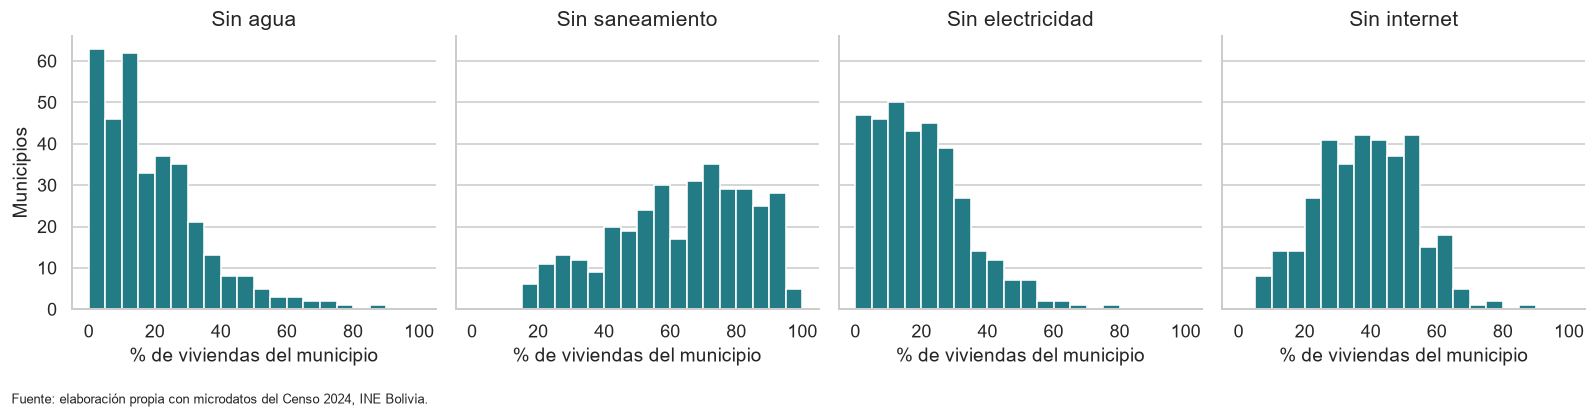

In [9]:
# histogramas de las cuatro variables de agrupamiento, en la misma escala
nombres = {"pct_sin_agua":"Sin agua", "pct_sin_saneamiento":"Sin saneamiento",
           "pct_sin_electricidad":"Sin electricidad", "pct_sin_internet":"Sin internet"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
for ax, columna in zip(axes, features):
    ax.hist(df[columna], bins=np.arange(0, 105, 5), color=COLOR, edgecolor="white")
    ax.set(title=nombres[columna], xlabel="% de viviendas del municipio")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False, axis="x")
axes[0].set_ylabel("Municipios")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Lectura:** las cuatro tasas tienen niveles muy distintos. La falta de saneamiento es la más alta (promedio de 63,5 %) y las de agua y electricidad, las más bajas (19,1 % y 20,3 %). Ningún histograma muestra jorobas separadas, primera señal de que no hay grupos muy marcados.

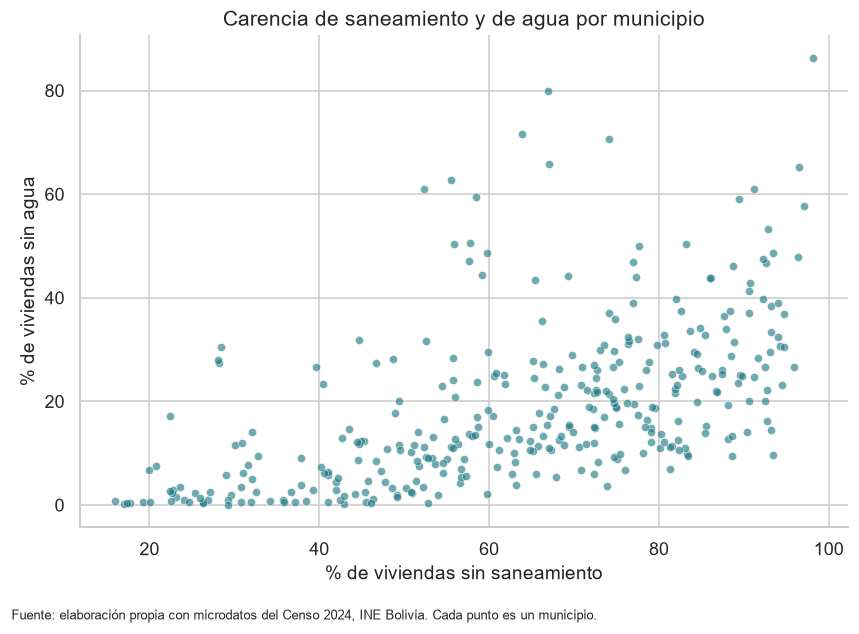

In [10]:
# ¿se ven grupos naturales antes de aplicar el modelo?
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(df["pct_sin_saneamiento"], df["pct_sin_agua"], s=26, alpha=0.65, color=COLOR, edgecolor="white", linewidth=0.4)
ax.set(title="Carencia de saneamiento y de agua por municipio",
       xlabel="% de viviendas sin saneamiento", ylabel="% de viviendas sin agua")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, FUENTE + " Cada punto es un municipio.", fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Lectura:** los municipios forman una nube continua, sin bloques separados. Al subir la falta de saneamiento, la falta de agua también tiende a subir, y además se abre: a partir de cerca de 50 % de saneamiento hay municipios con muy poca y con mucha falta de agua. Esa diferencia es la que puede dar perfiles distintos.

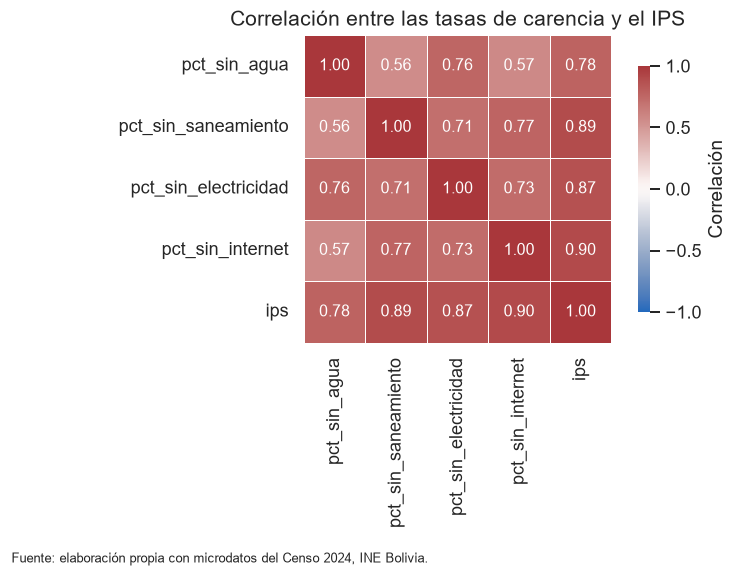

In [11]:
# mapa de correlaciones: una sola escala divergente con 0 como punto medio
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(df[features + ["ips"]].corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink":0.8, "label":"Correlación"}, ax=ax)
ax.set_title("Correlación entre las tasas de carencia y el IPS")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Lectura:** las carencias se mueven juntas (correlaciones de 0,56 a 0,77), pero no son idénticas. La falta de agua es la menos ligada a saneamiento e internet (0,56 y 0,57). El IPS se correlaciona de 0,78 a 0,90 con cada una porque se construye con ellas, otra razón para no usarlo como variable de agrupamiento.

# ACTIVIDAD PARTICIPATIVA 1: Reflexión conceptual

**1. Si tuvieras que agrupar 343 municipios a mano, ¿qué criterios usarías?**

Revisaría qué servicio falta en cada uno y separaría a los que tienen pocas carencias de los que tienen muchas. Luego distinguiría, entre estos últimos, los que además carecen de lo más básico: agua y electricidad. Hacerlo a mano con cuatro variables a la vez es lento y subjetivo; K-Means aplica un mismo criterio de distancia a todos.

**2. Mirando las variables, ¿cuántos grupos crees que existen? ¿Por qué?**

Según la exploración, no se esperan grupos naturales muy separados, porque las carencias suben casi juntas. Es razonable esperar pocos grupos, entre tres y cinco, que dividan ese recorrido, con alguna diferencia dada por el agua.

**3. ¿Qué columnas son más útiles para agrupar? ¿Por qué esas y no otras?**

Las cuatro tasas de carencia, porque responden a la pregunta del proyecto y están en la misma unidad. No se usan los códigos de departamento o municipio, porque son etiquetas sin distancia real, ni el IPS, porque repetiría la información.

**4. ¿Por qué es importante conocer los distintos tipos de municipio?**

Porque cada falta de servicio pide una respuesta distinta: llevar agua y electricidad no se organiza igual que ampliar saneamiento o internet. Un solo índice no permite ver esa diferencia.

# PARTE 3: PREPROCESAMIENTO

K-Means usa distancias, por lo que una variable con mayor dispersión pesaría más. Aquí todas están en porcentaje, pero su desviación estándar va de 13,97 (electricidad) a 20,75 (saneamiento). **StandardScaler** deja cada variable con media 0 y desviación estándar 1:

$$z = \frac{x - \mu}{\sigma}$$

Así, las cuatro carencias pesan lo mismo en la distancia. Es una decisión de método, y en el Paso 6 se revisa cuánto cambia el resultado sin ella. No hay faltantes que imputar.

In [12]:
# Aplicar StandardScaler: media 0 y desviación estándar 1 en cada variable
X = df[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)

print("ANTES (valores originales):")
print(X.agg(["mean", "std"]).round(2).to_string())
print("\nDESPUÉS (valores escalados):")
print(X_scaled_df.agg(["mean", "std"]).round(2).to_string())

ANTES (valores originales):
      pct_sin_agua  pct_sin_saneamiento  pct_sin_electricidad  pct_sin_internet
mean          19.1                63.50                 20.31             38.69
std           15.6                20.75                 13.97             14.71

DESPUÉS (valores escalados):
      pct_sin_agua  pct_sin_saneamiento  pct_sin_electricidad  pct_sin_internet
mean           0.0                 -0.0                   0.0              -0.0
std            1.0                  1.0                   1.0               1.0


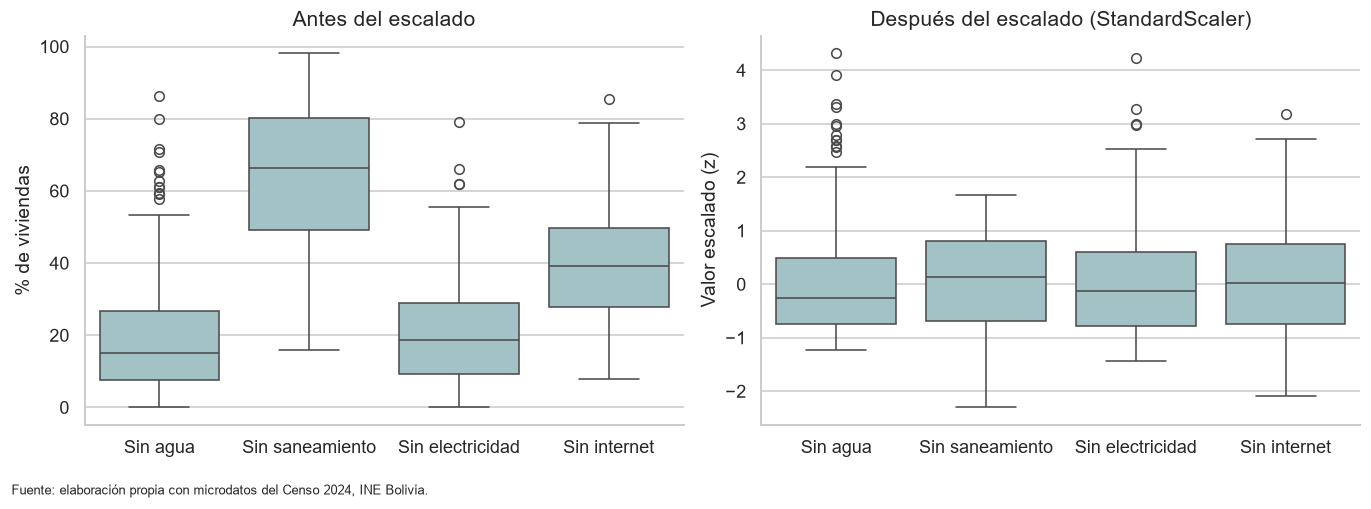

In [13]:
# efecto del escalado
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
sns.boxplot(data=X.rename(columns=nombres), color="#9cc7cb", linewidth=1, ax=axes[0])
axes[0].set(title="Antes del escalado", ylabel="% de viviendas")
sns.boxplot(data=X_scaled_df.rename(columns=nombres), color="#9cc7cb", linewidth=1, ax=axes[1])
axes[1].set(title="Después del escalado (StandardScaler)", ylabel="Valor escalado (z)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False, axis="x")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

# PARTE 4: IMPLEMENTACIÓN DE K-MEANS

## ¿Cómo elegir K?

- **Método del codo:** el K a partir del cual agregar grupos ya casi no reduce el WCSS.
- **Silueta:** compara cuán cerca está cada punto de su grupo frente al grupo vecino. Va de -1 a 1; más alto es mejor.
- **Davies-Bouldin:** promedia cuánto se parece cada grupo a su grupo más similar; más bajo es mejor.
- **Estabilidad (ARI):** repite el ajuste con inicios distintos y mide si sale la misma partición.

**Regla fijada:** K=2 solo separaría "más" de "menos" carencias, sin indicar qué servicio falta, por lo que se revisa aparte en la pregunta 5. Entre K=3 y K=6 se consideran empatados los valores a menos de 0,02 de la mejor silueta, y entre ellos gana el más estable.

In [14]:
# para cada K: compactación, separación y estabilidad frente al inicio aleatorio
k_range = range(2, 11)
filas = []
for k in k_range:
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_scaled)
    # ARI: 1 = misma partición, 0 = coincidencia como la del azar
    acuerdos = [adjusted_rand_score(modelo.labels_, KMeans(n_clusters=k, random_state=s, n_init=1).fit_predict(X_scaled))
                for s in range(20)]
    filas.append({"K":k, "WCSS":modelo.inertia_, "Silueta":silhouette_score(X_scaled, modelo.labels_),
                  "Davies-Bouldin":davies_bouldin_score(X_scaled, modelo.labels_),
                  "Estabilidad (ARI)":np.mean(acuerdos), "Grupo más pequeño":np.bincount(modelo.labels_).min()})
tabla_k = pd.DataFrame(filas).set_index("K")
tabla_k.insert(1, "Reducción de WCSS (%)", -100 * tabla_k["WCSS"].pct_change())
display(tabla_k.round(3))

# regla: entre los candidatos, los de silueta casi igual a la mejor; gana el más estable
candidatos = tabla_k.loc[K_CANDIDATOS]
empatados = candidatos[candidatos["Silueta"] >= candidatos["Silueta"].max() - TOLERANCIA_SILUETA]
K_OPTIMO = int(empatados["Estabilidad (ARI)"].idxmax())
print("K con silueta empatada:", list(empatados.index), "| K seleccionado:", K_OPTIMO)

,WCSS,Reducción de WCSS (%),Silueta,Davies-Bouldin,Estabilidad (ARI),Grupo más pequeño
K,,,,,,
2,650.080,NaN,0.434,0.862,0.994,162
3,485.697,25.287,0.324,1.045,0.844,101
4,382.190,21.311,0.313,1.115,0.857,53
5,329.736,13.725,0.320,1.098,0.748,39
6,294.145,10.794,0.286,1.162,0.804,30
7,265.274,9.815,0.283,1.153,0.739,14
8,241.571,8.935,0.283,1.124,0.694,11
9,225.936,6.472,0.280,1.148,0.661,8
10,211.726,6.289,0.282,1.157,0.668,11


K con silueta empatada: [3, 4, 5] | K seleccionado: 4


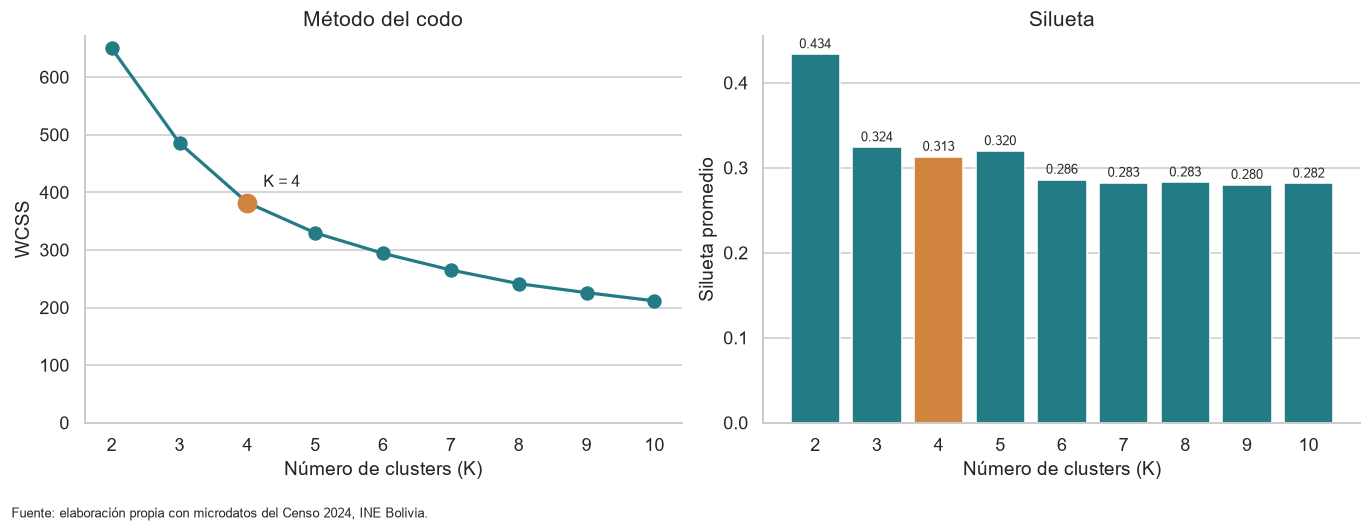

In [15]:
# método del codo y silueta: dos gráficos, cada uno con su propia escala
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(tabla_k.index, tabla_k["WCSS"], marker="o", markersize=8, linewidth=2, color=COLOR)
axes[0].scatter([K_OPTIMO], [tabla_k.loc[K_OPTIMO, "WCSS"]], s=130, color=REFERENCIA, zorder=3)
axes[0].annotate(f"K = {K_OPTIMO}", (K_OPTIMO, tabla_k.loc[K_OPTIMO, "WCSS"]), xytext=(10, 10), textcoords="offset points")
axes[0].set(title="Método del codo", xlabel="Número de clusters (K)", ylabel="WCSS", xticks=list(k_range), ylim=(0, None))

barras = axes[1].bar(tabla_k.index, tabla_k["Silueta"], color=[REFERENCIA if k == K_OPTIMO else COLOR for k in tabla_k.index], edgecolor="white")
axes[1].bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
axes[1].set(title="Silueta", xlabel="Número de clusters (K)", ylabel="Silueta promedio", xticks=list(k_range))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False, axis="x")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Interpretación:** K=2 tiene la mayor silueta (0,434), como en el ejemplo de iFood, pero no responde a la pregunta. Entre los candidatos empatan K=3, 4 y 5 (0,324; 0,313 y 0,320), y la regla elige **K=4**, el más estable (ARI de 0,857). El codo apoya la elección: el WCSS baja 25,3 % y 21,3 % al pasar a K=3 y K=4, y luego solo 13,7 %. La ventaja frente a K=3 es pequeña (0,857 frente a 0,844), así que **K=4 es una elección razonable, no un número natural de los datos**.

## Entrenar el modelo

- `n_clusters`: el K seleccionado.
- `random_state=42`: reproducibilidad.
- `n_init=20`: repite el algoritmo con 20 inicios distintos y conserva el de menor WCSS.

In [16]:
# Entrenar el modelo K-Means
kmeans = KMeans(n_clusters=K_OPTIMO, random_state=RANDOM_STATE, n_init=N_INIT)
etiquetas = kmeans.fit_predict(X_scaled)

# K-Means numera los clusters al azar: se renumeran de menor a mayor IPS para que el orden tenga significado
orden_ips = df.groupby(etiquetas)["ips"].mean().sort_values().index
renumerar = {anterior: nuevo for nuevo, anterior in enumerate(orden_ips, start=1)}
df["Cluster"] = pd.Series(etiquetas, index=df.index).map(renumerar)

print(f"K = {K_OPTIMO} | WCSS: {kmeans.inertia_:,.2f} | iteraciones: {kmeans.n_iter_}")
display(df.groupby("Cluster").agg(Municipios=("ips","size"), Viviendas=("n_viviendas","sum")).assign(
    pct_municipios=lambda t: (100*t["Municipios"]/t["Municipios"].sum()).round(1),
    pct_viviendas=lambda t: (100*t["Viviendas"]/t["Viviendas"].sum()).round(1)))

K = 4 | WCSS: 382.19 | iteraciones: 19


,Municipios,Viviendas,pct_municipios,pct_viviendas
Cluster,,,,
1,86,1852968,25.1,70.3
2,109,359247,31.8,13.6
3,95,295622,27.7,11.2
4,53,127320,15.5,4.8


## Visualización de los clusters

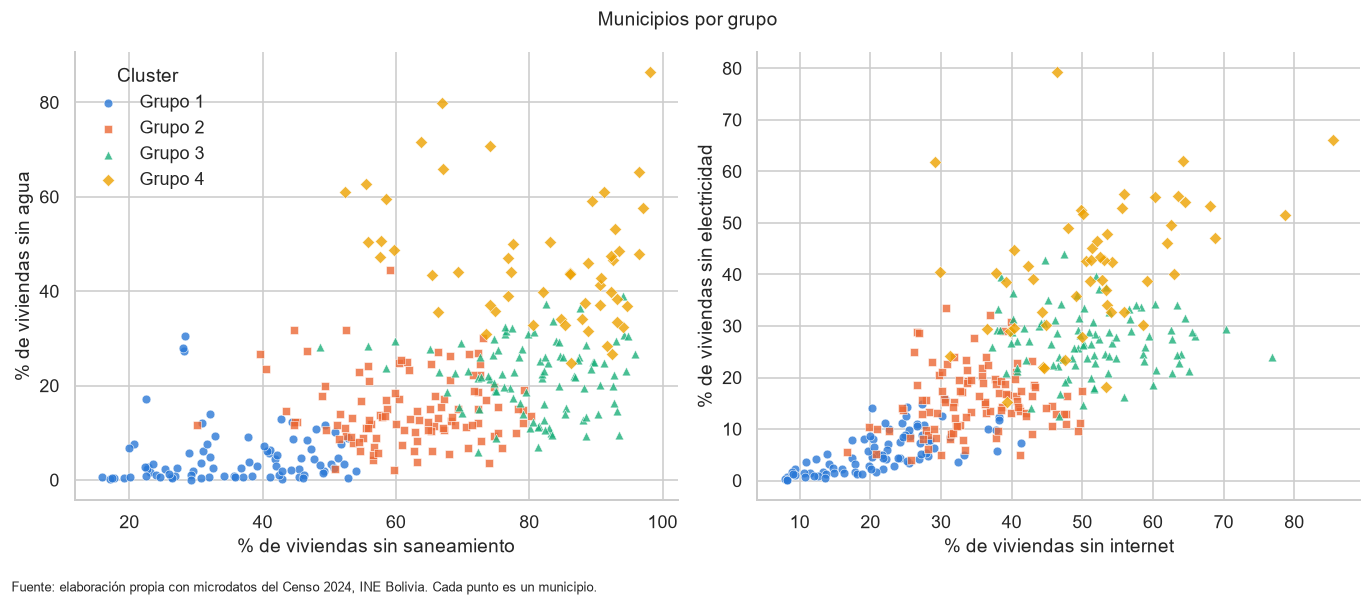

In [17]:
# dos pares de variables: se usa color y forma para identificar cada grupo
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (x_col, y_col) in zip(axes, [("pct_sin_saneamiento", "pct_sin_agua"), ("pct_sin_internet", "pct_sin_electricidad")]):
    for c in sorted(df["Cluster"].unique()):
        t = df[df["Cluster"] == c]
        ax.scatter(t[x_col], t[y_col], s=30, alpha=0.8, color=COLORES[c], marker=MARCAS[c],
                   edgecolor="white", linewidth=0.4, label=f"Grupo {c}")
    ax.set(xlabel=f"% de viviendas {nombres[x_col].lower()}", ylabel=f"% de viviendas {nombres[y_col].lower()}")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(title="Cluster", frameon=False, loc="upper left")
fig.suptitle("Municipios por grupo")
fig.text(0.01, 0.01, FUENTE + " Cada punto es un municipio.", fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Lectura:** el gráfico de la izquierda muestra lo más útil. Los grupos 3 y 4 se solapan en saneamiento, pero el grupo 4 queda por encima en falta de agua. A la derecha sucede algo parecido con la electricidad. Las fronteras entre grupos son contiguas, sin espacios vacíos.

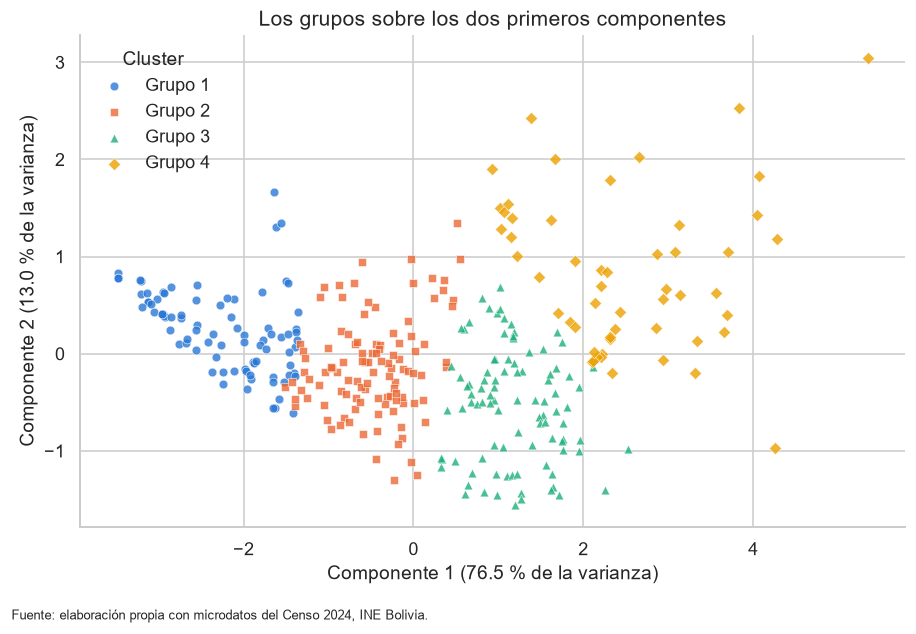

Varianza de los dos componentes: 76.5 % y 13.0 %


,Componente 1,Componente 2
pct_sin_agua,0.470,0.728
pct_sin_saneamiento,0.499,-0.484
pct_sin_electricidad,0.525,0.223
pct_sin_internet,0.505,-0.431


In [18]:
# PCA solo para dibujar las cuatro dimensiones en dos; K-Means no lo usa
pca = PCA(n_components=2, random_state=RANDOM_STATE)
componentes = pca.fit_transform(X_scaled)
varianza = 100 * pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(8, 5.5))
for c in sorted(df["Cluster"].unique()):
    marca = (df["Cluster"] == c).to_numpy()
    ax.scatter(componentes[marca, 0], componentes[marca, 1], s=30, alpha=0.8, color=COLORES[c], marker=MARCAS[c],
               edgecolor="white", linewidth=0.4, label=f"Grupo {c}")
ax.set(title="Los grupos sobre los dos primeros componentes",
       xlabel=f"Componente 1 ({varianza[0]:.1f} % de la varianza)", ylabel=f"Componente 2 ({varianza[1]:.1f} % de la varianza)")
ax.legend(title="Cluster", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
print(f"Varianza de los dos componentes: {varianza[0]:.1f} % y {varianza[1]:.1f} %")
display(pd.DataFrame(pca.components_.T, index=features, columns=["Componente 1", "Componente 2"]).round(3))

**Lectura:** el primer componente concentra **76,5 % de la varianza** y sus cuatro pesos son casi iguales (0,47 a 0,53): mide la carencia general. Los grupos 1, 2 y 3 son tramos sucesivos de ese eje. El segundo componente (13,0 %) separa la falta de agua y electricidad (positivo) de la de saneamiento e internet (negativo), y es donde el grupo 4 se aparta. **Los datos se parecen más a un gradiente continuo que a grupos separados**: K-Means lo divide en tramos útiles para describir, pero esas fronteras no son naturales.

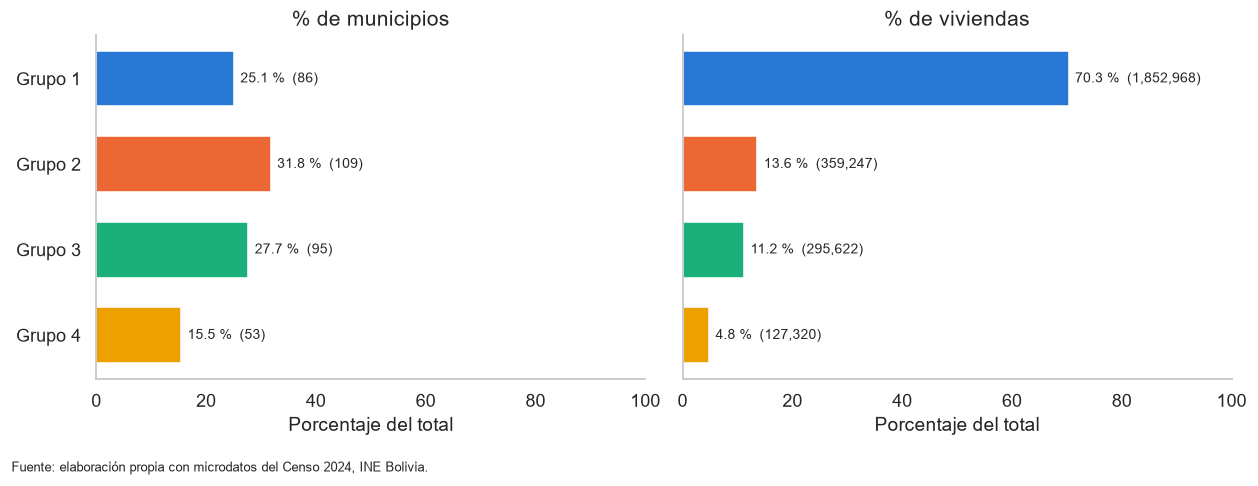

In [19]:
# el mismo grupo pesa distinto si se cuentan municipios o viviendas
conteo = df.groupby("Cluster").agg(Municipios=("ips","size"), Viviendas=("n_viviendas","sum"))
porcentajes = 100 * conteo / conteo.sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, columna in zip(axes, conteo.columns):
    barras = ax.barh([f"Grupo {c}" for c in conteo.index], porcentajes[columna], color=[COLORES[c] for c in conteo.index], height=0.65)
    ax.bar_label(barras, labels=[f"{p:.1f} %  ({v:,})" for p, v in zip(porcentajes[columna], conteo[columna])], padding=4, fontsize=9)
    ax.set(title=f"% de {columna.lower()}", xlabel="Porcentaje del total", xlim=(0, 100))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
axes[0].invert_yaxis()
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Lectura:** los dos conteos cuentan historias muy distintas. El grupo 1 reúne un cuarto de los municipios y casi tres cuartos de las viviendas clasificables, mientras que el grupo 4 tiene 15,5 % de los municipios y solo 4,8 % de las viviendas.

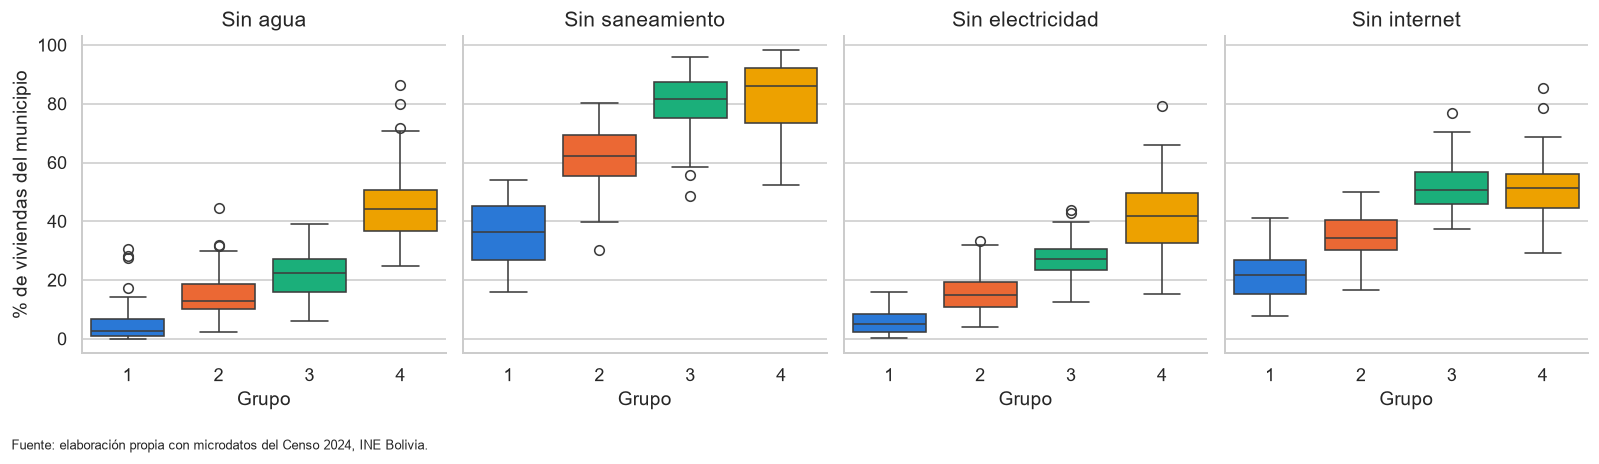

In [20]:
# distribución de cada tasa de carencia por grupo
largo = df.reset_index().melt(id_vars="Cluster", value_vars=features, var_name="Variable", value_name="Porcentaje")
largo["Variable"] = largo["Variable"].map(nombres)
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
for ax, nombre in zip(axes, nombres.values()):
    sns.boxplot(data=largo[largo["Variable"] == nombre], x="Cluster", y="Porcentaje", hue="Cluster",
                palette=COLORES, saturation=1, legend=False, linewidth=1, ax=ax)
    ax.set(title=nombre, xlabel="Grupo", ylabel="")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False, axis="x")
axes[0].set_ylabel("% de viviendas del municipio")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Lectura:** en saneamiento e internet, las cajas de los grupos 3 y 4 casi coinciden. En agua y electricidad, el grupo 4 se separa hacia arriba. Esa es la diferencia que el IPS por sí solo no deja ver.

## Perfilado de clusters

El perfilado describe cada grupo para darle un nombre útil. El mapa muestra el valor promedio y, con color, cuánto se aleja del promedio de los municipios. El IPS se muestra como referencia, pero **no valida los grupos**, porque se calcula con las mismas carencias que los forman. Las características de la vivienda sí son información que el modelo no vio.

In [21]:
# perfil promedio de cada cluster: variables de agrupamiento y variables de contexto
cluster_profile = df.groupby("Cluster")[features + ["ips"] + contexto + ["cobertura"]].mean().round(1)
cluster_profile.T

Cluster,1,2,3,4
pct_sin_agua,4.8,14.7,21.8,46.4
pct_sin_saneamiento,35.8,61.9,80.6,81.0
pct_sin_electricidad,5.7,15.6,27.1,41.6
pct_sin_internet,21.6,35.0,51.3,51.5
ips,15.0,36.3,58.6,70.0
pct_rural,32.1,71.0,92.2,96.6
pct_piso_tierra,16.2,33.9,58.8,65.1
pct_pared_no_ladrillo,26.7,56.1,75.3,80.1
pct_techo_paja,3.3,8.5,16.3,29.5
pct_basura_sin_servicio,35.0,62.4,84.8,91.7


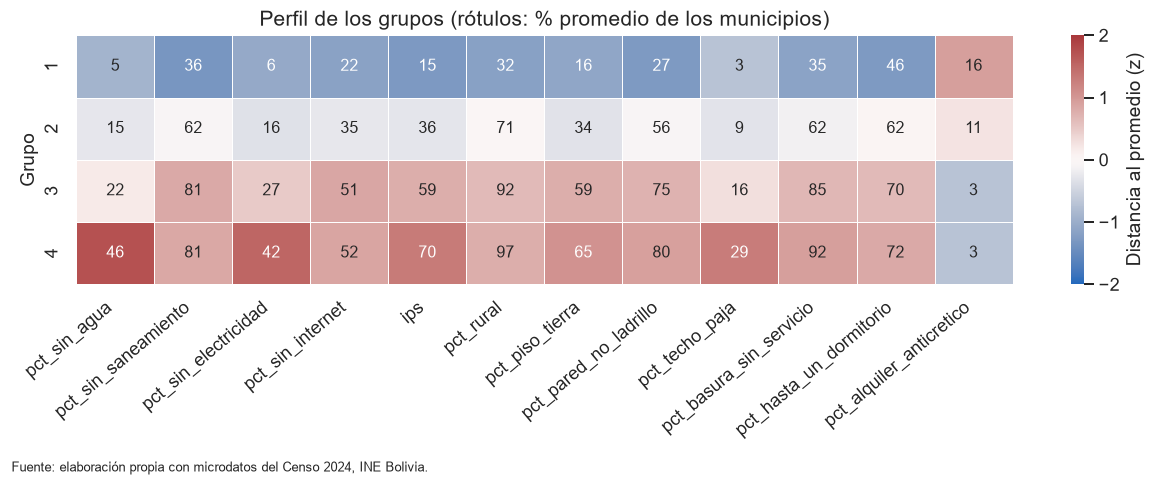

In [22]:
# z = distancia al promedio de los municipios, en desviaciones estándar; el rótulo muestra el % real
columnas_mapa = features + ["ips"] + contexto
perfil_z = (df.groupby("Cluster")[columnas_mapa].mean() - df[columnas_mapa].mean()) / df[columnas_mapa].std()
fig, ax = plt.subplots(figsize=(11, 4.2))
sns.heatmap(perfil_z, annot=df.groupby("Cluster")[columnas_mapa].mean().round(0), fmt=".0f", cmap="vlag", center=0, vmin=-2, vmax=2,
            linewidths=0.5, cbar_kws={"label":"Distancia al promedio (z)"}, ax=ax)
ax.set(title="Perfil de los grupos (rótulos: % promedio de los municipios)", ylabel="Grupo", xlabel="")
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Lectura:** las características de la vivienda, que el modelo no usó, cambian de forma coherente entre los grupos: el piso de tierra pasa de 16 % a 65 % y el área rural, de 32 % a 97 %. Eso da respaldo externo a la partición, aunque no prueba que una cosa cause la otra. Solo el techo de paja separa con claridad los grupos 3 y 4 (16 % y 29 %); en las demás características, ambos grupos son más parecidos.

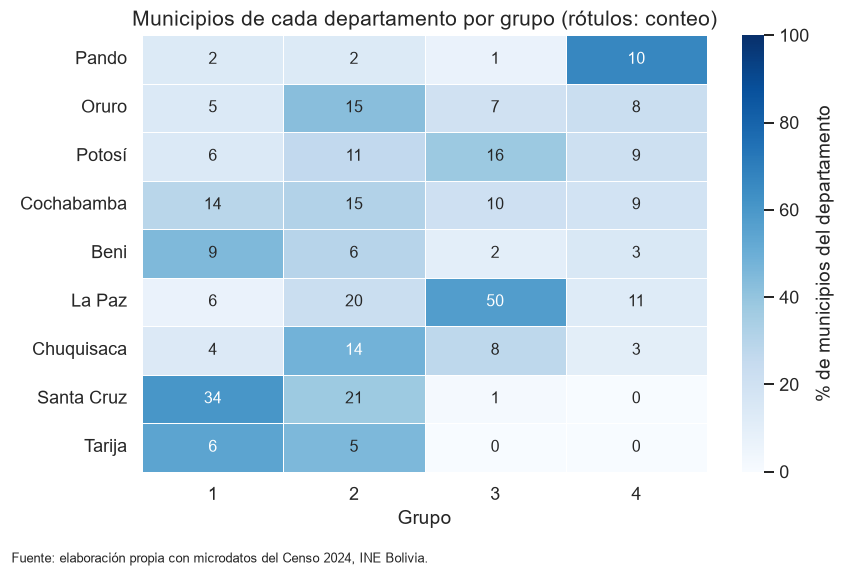

Cluster,1,2,3,4
departamento,,,,
Pando,2,2,1,10
Oruro,5,15,7,8
Potosí,6,11,16,9
Cochabamba,14,15,10,9
Beni,9,6,2,3
La Paz,6,20,50,11
Chuquisaca,4,14,8,3
Santa Cruz,34,21,1,0
Tarija,6,5,0,0


In [23]:
# composición territorial: el departamento no se usó para formar los grupos
composicion = pd.crosstab(df["departamento"], df["Cluster"])
porcentaje_dep = 100 * composicion.div(composicion.sum(axis=1), axis=0)
orden_dep = porcentaje_dep[K_OPTIMO].sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(porcentaje_dep.loc[orden_dep], annot=composicion.loc[orden_dep], fmt="d", cmap="Blues", vmin=0, vmax=100,
            linewidths=0.5, cbar_kws={"label":"% de municipios del departamento"}, ax=ax)
ax.set(title="Municipios de cada departamento por grupo (rótulos: conteo)", xlabel="Grupo", ylabel="")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
display(composicion.loc[orden_dep])

**Lectura:** el departamento no se usó y aun así hay patrones: 50 de los 87 municipios de La Paz están en el grupo 3, 10 de los 15 de Pando en el grupo 4, y Santa Cruz (55 de 56) y Tarija (11 de 11) quedan casi por completo en los grupos 1 y 2. Pando coincide con la advertencia de la regresión lineal, donde el modelo también falló. Ningún departamento pertenece por entero a un grupo, por lo que la revisión debe hacerse por municipio.

## Etiquetas de los clusters

Los nombres son una interpretación de los valores anteriores. Los porcentajes son promedios de los municipios de cada grupo.

| Grupo | Nombre | Descripción |
|---|---|---|
| 1 | **Menor carencia** | Más urbano (32 % rural). Sin agua 5 %, sin electricidad 6 %. Aun así, 36 % sin saneamiento y 22 % sin internet. |
| 2 | **Carencia intermedia** | Principalmente saneamiento (62 %) e internet (35 %); agua y electricidad cerca de 15 %. |
| 3 | **Saneamiento e internet críticos** | Rural (92 %). Sin saneamiento 81 %, sin internet 51 %; agua (22 %) y electricidad (27 %) en niveles moderados. |
| 4 | **Carencia múltiple, con falta de agua y electricidad** | Rural (97 %). Mismo nivel que el grupo 3 en saneamiento e internet, pero con el doble de falta de agua (46 %) y más falta de electricidad (42 %). |

## ¿Cuántas viviendas hay detrás de cada tasa?

In [24]:
# la tasa más alta no implica la mayor cantidad de viviendas afectadas
afectadas = df.assign(precarias=df["ips"] / 100 * df["n_viviendas"]).groupby("Cluster").agg(
    Viviendas=("n_viviendas", "sum"), precarias=("precarias", "sum")).rename(columns={"precarias":"Viviendas precarias"})
afectadas["% con dos o más carencias"] = 100 * afectadas["Viviendas precarias"] / afectadas["Viviendas"]
afectadas["% del total nacional"] = 100 * afectadas["Viviendas precarias"] / afectadas["Viviendas precarias"].sum()
assert round(100 * afectadas["Viviendas precarias"].sum() / afectadas["Viviendas"].sum(), 2) == round(ips_nacional, 2)
afectadas.round(1)

,Viviendas,Viviendas precarias,% con dos o más carencias,% del total nacional
Cluster,,,,
1,1852968,119751.0,6.5,23.2
2,359247,134366.0,37.4,26.0
3,295622,173896.0,58.8,33.7
4,127320,88481.0,69.5,17.1


**Lectura:** el grupo 4 tiene la mayor proporción de viviendas con dos o más carencias (69,5 %), pero solo 17,1 % del total de esas viviendas (88.481). El **grupo 3** concentra la mayor cantidad (173.896; 33,7 %). El grupo 1 tiene la proporción más baja (6,5 %), pero aun así reúne 119.751 viviendas (23,2 %), por su tamaño. Una acción dirigida solo a la tasa más alta dejaría fuera a más de 80 % de las viviendas afectadas. Las dos miradas responden a preguntas distintas: **dónde es más grave** y **dónde hay más viviendas**.

El 6,5 % del grupo 1 pondera por viviendas; el 15 % del mapa anterior promedia municipios, y por eso difieren.

**Municipios representativos.** El censo solo trae códigos, así que se identifican por código y departamento. Estos son ejemplos de cada perfil, no los municipios con mayores carencias.

In [25]:
# municipios más representativos: los tres más cercanos al centroide de su grupo
centroides = df.assign(**X_scaled_df).groupby("Cluster")[features].mean()
distancia = np.linalg.norm(X_scaled_df.to_numpy() - centroides.loc[df["Cluster"]].to_numpy(), axis=1)
representativos = (df.assign(distancia=distancia).sort_values("distancia").groupby("Cluster").head(3)
                   .sort_values(["Cluster", "distancia"])[["Cluster", "departamento", "n_viviendas"] + features + ["ips"]])
representativos.round(1)

,Cluster,departamento,n_viviendas,pct_sin_agua,pct_sin_saneamiento,pct_sin_electricidad,pct_sin_internet,ips
municipio,,,,,,,,
030902,1,Cochabamba,10763,6.2,40.6,7.1,22.5,17.7
071004,1,Santa Cruz,2145,0.9,35.8,5.8,19.7,12.8
070503,1,Santa Cruz,3113,3.5,30.8,4.3,24.2,13.2
010701,2,Chuquisaca,3462,14.6,63.2,15.3,31.9,36.6
041502,2,Oruro,273,17.2,60.4,17.2,33.0,32.2
031301,2,Cochabamba,4994,15.1,65.1,19.0,33.6,39.5
020307,3,La Paz,628,21.7,81.8,29.3,49.4,62.9
021201,3,La Paz,10528,18.9,75.0,28.2,49.7,55.4
021306,3,La Paz,2594,22.0,86.8,28.8,53.8,58.9


# ACTIVIDAD PARTICIPATIVA 2: Interpretación de clusters

**1. ¿Qué grupo debería revisarse primero? ¿Por qué?**

Depende del criterio. Por gravedad, el **grupo 4**: mayor IPS (70 %) y falta simultánea de los cuatro servicios, incluidos agua y electricidad. Por cantidad, el **grupo 3**, que tiene el mayor número de viviendas con dos o más carencias (173.896). El dato no decide por sí solo: es una decisión de política.

**2. ¿Qué acción se propondría para cada grupo?**

Estas son **propuestas de trabajo, no resultados del modelo**. Requieren verificar costos y condiciones locales.

- **Grupo 1:** enfocar saneamiento en las zonas concretas que no lo tienen; la proporción es baja, pero son 119.751 viviendas con dos o más carencias.
- **Grupo 2:** priorizar saneamiento y conectividad, antes de que el municipio se acerque al perfil del grupo 3.
- **Grupo 3:** soluciones de saneamiento adecuadas a zonas rurales y ampliación de internet.
- **Grupo 4:** primero agua y electricidad, y revisar antes los datos de los municipios con cobertura baja.

**3. Mirando la silueta y el codo, ¿cambiarías K?**

Se mantendría K=4 para este fin, porque es el más estable entre los empatados y separa el perfil con falta de agua. Pero K=3 y K=5 tienen métricas casi iguales, y K=2 es la división más clara si solo interesa separar más y menos carencias. Para otro fin, otro K puede ser mejor.

**4. ¿Qué otras variables añadirías?**

Desde el censo de personas: educación y actividad económica, para describir mejor los grupos. También la distancia a centros urbanos y datos de inversión pública, que no están en este archivo. Se usarían primero para describir, no para formar los grupos, porque no miden qué servicio falta.

**5. Si solo pudieras tener dos grupos, ¿cómo los combinarías?**

La lógica sería unir 1 con 2 y 3 con 4, separando menor de mayor carencia. La tabla siguiente comprueba si K-Means con K=2 hace lo mismo.

In [26]:
# pregunta 5: ¿qué pasa al pedir solo dos grupos?
dos_grupos = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X_scaled)
# se numera 1 al grupo de menor IPS
if df.groupby(dos_grupos)["ips"].mean().idxmin() == 1:
    dos_grupos = 1 - dos_grupos
dos_grupos = dos_grupos + 1
display(pd.crosstab(df["Cluster"], dos_grupos, rownames=["Grupo con K=4"], colnames=["Grupo con K=2"]))
display(df.groupby(dos_grupos)[features + ["ips"]].mean().round(1).rename_axis("Grupo con K=2"))

Grupo con K=2,1,2
Grupo con K=4,,
1,86,0
2,95,14
3,0,95
4,0,53


,pct_sin_agua,pct_sin_saneamiento,pct_sin_electricidad,pct_sin_internet,ips
Grupo con K=2,,,,,
1,9.2,49.2,10.3,28.5,25.5
2,30.2,79.5,31.5,50.1,61.2


**Respuesta:** coincide casi por completo. Los grupos 1, 3 y 4 caen por entero en un solo lado; solo 14 municipios del grupo 2 pasan al lado de mayor carencia. Con K=2 se gana claridad, pero **se pierde justo lo que motiva este análisis**: la diferencia entre los grupos 3 y 4 en agua y electricidad.

# PARTE 5: EVALUACIÓN Y MÉTRICAS

En clustering no hay una respuesta correcta, así que se mide la calidad interna y la solidez de los grupos. Estas métricas **no indican si los grupos son útiles**: eso se juzga con la interpretación anterior.

| Métrica | Qué mide | Mejor valor |
|---|---|---|
| **WCSS (inercia)** | Dispersión dentro de los grupos | Más bajo, a igual K |
| **Silueta** | Cohesión y separación | Más cercano a 1 |
| **Davies-Bouldin** | Parecido entre grupos vecinos | Más bajo |
| **ARI** | Coincidencia entre dos particiones | 1 = idénticas, 0 = como al azar |

In [27]:
# Evaluación del modelo final
silhouette_final = silhouette_score(X_scaled, df["Cluster"])
wcss_final = kmeans.inertia_
wcss_total = ((X_scaled - X_scaled.mean(axis=0))**2).sum()
print(f"Número de clusters : {K_OPTIMO}")
print(f"WCSS (inercia)     : {wcss_final:,.2f}")
print(f"Varianza explicada : {100 * (1 - wcss_final / wcss_total):.1f} %")
print(f"Silueta            : {silhouette_final:.4f}")
print(f"Davies-Bouldin     : {davies_bouldin_score(X_scaled, df['Cluster']):.4f}")

if silhouette_final > 0.7:
    interpretacion = "Excelente: clusters muy bien definidos"
elif silhouette_final > 0.5:
    interpretacion = "Bueno: clusters razonablemente bien definidos"
elif silhouette_final > 0.25:
    interpretacion = "Aceptable: hay superposición entre clusters"
else:
    interpretacion = "Débil: los clusters se solapan mucho"
print("Interpretación     :", interpretacion)

Número de clusters : 4
WCSS (inercia)     : 382.19
Varianza explicada : 72.1 %
Silueta            : 0.3131
Davies-Bouldin     : 1.1146
Interpretación     : Aceptable: hay superposición entre clusters


,Promedio,Mínimo,Negativos
Cluster,,,
1,0.422,0.040,0
2,0.292,-0.041,3
3,0.341,0.011,0
4,0.130,-0.157,14


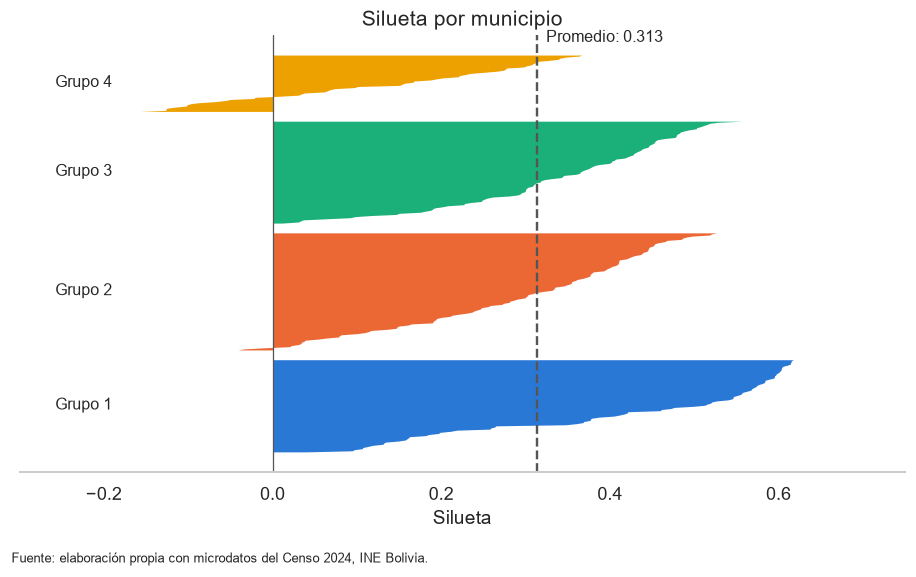

In [28]:
# silueta de cada municipio: un valor negativo indica que está más cerca de otro grupo
df["silueta"] = silhouette_samples(X_scaled, df["Cluster"])
display(df.groupby("Cluster")["silueta"].agg(Promedio="mean", Mínimo="min", Negativos=lambda s: int((s < 0).sum())).round(3))

fig, ax = plt.subplots(figsize=(8, 5))
base = 0
for c in sorted(df["Cluster"].unique()):
    valores = df.loc[df["Cluster"] == c, "silueta"].sort_values().to_numpy()
    ax.fill_betweenx(np.arange(base, base + len(valores)), 0, valores, color=COLORES[c], linewidth=0)
    ax.text(-0.19, base + len(valores)/2, f"Grupo {c}", va="center", ha="right")
    base += len(valores) + 8
ax.axvline(silhouette_final, color="#555555", linestyle="--", linewidth=1.5)
ax.annotate(f"Promedio: {silhouette_final:.3f}", (silhouette_final, base), xytext=(6, 0), textcoords="offset points", va="bottom")
ax.set(title="Silueta por municipio", xlabel="Silueta", yticks=[], xlim=(-0.3, 0.75))
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(False)
ax.axvline(0, color="#555555", linewidth=0.8)
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Interpretación:** la silueta de 0,313 indica grupos reconocibles pero con superposición, coherente con el gradiente de la PCA. **El grupo 4 es el menos compacto**: silueta de 0,130 y 14 de sus 53 municipios con valor negativo, es decir, más cerca de otro grupo. Comparte un perfil general, pero es heterogéneo y no conviene tratarlo como un bloque uniforme. El grupo 1 es el mejor definido (0,422).

## Solidez de los grupos

In [29]:
# ¿los grupos se mantienen si cambian los datos o el preprocesamiento?
def agrupar(datos):
    return KMeans(n_clusters=K_OPTIMO, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(datos)

referencia = df["Cluster"].to_numpy()
generador = np.random.default_rng(RANDOM_STATE)

# 1. submuestras aleatorias del 80 % de los municipios
acuerdos_sub = []
for _ in range(50):
    idx = generador.choice(len(df), size=int(0.8 * len(df)), replace=False)
    acuerdos_sub.append(adjusted_rand_score(referencia[idx], agrupar(X_scaled[idx])))

# 2. sin municipios de cobertura menor a 50 %
alta = (df["cobertura"] >= 50).to_numpy()

# 3. sin escalar las variables
sensibilidad = pd.DataFrame([
    {"Prueba":"Submuestras del 80 % (50 repeticiones)", "Municipios":int(0.8 * len(df)), "ARI":np.mean(acuerdos_sub), "ARI mínimo":np.min(acuerdos_sub)},
    {"Prueba":"Solo cobertura de 50 % o más", "Municipios":int(alta.sum()),
     "ARI":adjusted_rand_score(referencia[alta], agrupar(StandardScaler().fit_transform(X[alta]))), "ARI mínimo":np.nan},
    {"Prueba":"Sin escalar las variables", "Municipios":len(df), "ARI":adjusted_rand_score(referencia, agrupar(X.to_numpy())), "ARI mínimo":np.nan},
]).set_index("Prueba")
display(sensibilidad.round(3))

display(df.groupby("Cluster").agg(Cobertura_media=("cobertura","mean"),
        Cobertura_menor_50=("cobertura", lambda s: int((s < 50).sum()))).round(1))

,Municipios,ARI,ARI mínimo
Prueba,,,
Submuestras del 80 % (50 repeticiones),274,0.845,0.664
Solo cobertura de 50 % o más,269,0.891,NaN
Sin escalar las variables,343,0.841,NaN


,Cobertura_media,Cobertura_menor_50
Cluster,,
1,62.8,20
2,63.1,23
3,65.2,14
4,59.3,17


**Interpretación:** la partición es bastante sólida. Con submuestras del 80 %, el ARI promedio es 0,845, aunque en el peor caso baja a 0,664, y cambia poco al quitar los municipios de baja cobertura (0,891) o no escalar (0,841). La cobertura media es parecida entre grupos (59,3 % a 65,2 %), de modo que no parece ser la causa de la partición. Aun así, 74 municipios tienen cobertura menor a 50 %, y su grupo es menos seguro.

In [30]:
# ¿qué pasa si los grupos se forman con otras variables? Mismo K para comparar
def resumen_variables(nombre, columnas):
    datos = StandardScaler().fit_transform(df[columnas])
    etiquetas_alt = KMeans(n_clusters=K_OPTIMO, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(datos)
    return {"Variables":nombre, "Cantidad":len(columnas), "Silueta":silhouette_score(datos, etiquetas_alt),
            "ARI con el modelo final":adjusted_rand_score(df["Cluster"], etiquetas_alt)}

display(pd.DataFrame([resumen_variables("Tasas de carencia (modelo final)", features),
                      resumen_variables("Solo contexto de la vivienda", contexto),
                      resumen_variables("Carencias y contexto", features + contexto)]).set_index("Variables").round(3))

,Cantidad,Silueta,ARI con el modelo final
Variables,,,
Tasas de carencia (modelo final),4,0.313,1.000
Solo contexto de la vivienda,7,0.254,0.305
Carencias y contexto,11,0.255,0.546


**Interpretación:** las tasas de carencia dan la mayor silueta (0,313 frente a 0,254 y 0,255), aunque es una comparación limitada, porque cada silueta se mide con variables distintas. Con solo las características de la vivienda, la partición coincide poco con la final (ARI de 0,305): están relacionadas, pero no son intercambiables. Por eso la elección de variables se justifica sobre todo por la pregunta del proyecto, qué servicio falta, y no solo por esta métrica.

# CONCLUSIONES

## Limitaciones

- **Gradiente, no grupos naturales:** K-Means siempre devuelve K grupos. Los municipios cercanos a una frontera podrían pertenecer a cualquiera de los dos lados.
- **Peso igual por municipio:** se trata igual a un municipio con 117 viviendas clasificables y a uno con 379.706. Los pequeños tienen tasas más inestables.
- **Cobertura:** 27,28 % de las viviendas analíticas no tiene clase y la cobertura va de 21,14 % a 95,86 %. Quienes quedan fuera pueden diferir de quienes están incluidos, y eso afecta a las tasas.
- **Promedios municipales:** dentro de un municipio puede haber realidades muy distintas. Un grupo no describe a cada vivienda (falacia ecológica).
- **Sin causalidad:** los perfiles describen un solo censo. Las características de contexto se asocian con los grupos, pero no los explican.
- **Decisiones de método:** el resultado depende de las variables, del escalado y de K. Las pruebas del Paso 6 reducen ese riesgo, pero no lo eliminan.

## Resultado

In [31]:
peso = 100 * df.groupby("Cluster")["n_viviendas"].sum() / df["n_viviendas"].sum()
tamano = df.groupby("Cluster").size()
display(Markdown(
    f"Se agruparon **{len(df)} municipios**, que resumen **{int(df['n_viviendas'].sum()):,} viviendas clasificables**, según sus cuatro tasas de carencia. "
    f"El modelo K-Means con **K={K_OPTIMO}** explica **{100*(1-wcss_final/wcss_total):.1f} %** de la varianza, con una silueta de **{silhouette_final:.3f}**, "
    f"lo que indica grupos reconocibles pero con superposición. El grupo {K_OPTIMO} reúne **{tamano[K_OPTIMO]} municipios** "
    f"({100*tamano[K_OPTIMO]/len(df):.1f} %), pero solo **{peso[K_OPTIMO]:.1f} %** de las viviendas clasificables; el grupo 1 reúne "
    f"**{tamano[1]} municipios** y **{peso[1]:.1f} %** de esas viviendas. El grupo con mayor tasa no es el que concentra más viviendas "
    f"con dos o más carencias: el grupo {afectadas['Viviendas precarias'].idxmax()} tiene **{afectadas['Viviendas precarias'].max():,.0f}** de ellas "
    f"({afectadas['% del total nacional'].max():.1f} %), frente a **{afectadas.loc[K_OPTIMO, 'Viviendas precarias']:,.0f}** del grupo {K_OPTIMO}. La partición sirve para organizar una revisión territorial; "
    "no demuestra causas ni separa tipos de municipio claramente distintos."
))

Se agruparon **343 municipios**, que resumen **2,635,157 viviendas clasificables**, según sus cuatro tasas de carencia. El modelo K-Means con **K=4** explica **72.1 %** de la varianza, con una silueta de **0.313**, lo que indica grupos reconocibles pero con superposición. El grupo 4 reúne **53 municipios** (15.5 %), pero solo **4.8 %** de las viviendas clasificables; el grupo 1 reúne **86 municipios** y **70.3 %** de esas viviendas. El grupo con mayor tasa no es el que concentra más viviendas con dos o más carencias: el grupo 3 tiene **173,896** de ellas (33.7 %), frente a **88,481** del grupo 4. La partición sirve para organizar una revisión territorial; no demuestra causas ni separa tipos de municipio claramente distintos.

**Trabajo posterior:** repetir el agrupamiento con ponderación por número de viviendas, revisar los municipios con cobertura baja, añadir nombres oficiales de municipios y contrastar los grupos con métodos que no requieran fijar K, como el clustering jerárquico.

## Fuente de los datos

**Instituto Nacional de Estadística (INE) de Bolivia.** Microdatos oficiales del **Censo de Población y Vivienda 2024**, archivo `Vivienda_CPV-2024.csv`; categorías contrastadas con `data/Diccionario de variables CPV 2024.xlsx`. Las reglas de población y de carencia se reproducen de `entendimiento de datos.ipynb`. Las tasas municipales, las tablas, las figuras y los grupos son elaboración propia.